# Experiment 9: Differential Evolution (DE)

**Aim:** To implement a simple Differential Evolution algorithm for solving an optimization problem using Python.

**Theory:** DE evolves a population using vector differences: mutant v = a + F·(b − c) from three random individuals, binomial crossover with rate CR to make a trial vector, and greedy selection keeping the better of trial and target. Problem: minimise the Rastrigin function (many local minima, global minimum 0 at the origin).

**Step 0:** Import the required libraries and fix the random seed.

In [1]:
import random, numpy as np
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42)

**Step 1:** Define the Rastrigin function.

In [2]:
def rastrigin(x):
    x = np.asarray(x); return float(10*len(x) + np.sum(x**2 - 10*np.cos(2*np.pi*x)))

**Step 2:** Implement DE (mutation, crossover, selection).

In [3]:
def de(func, dim=2, n=40, iters=100, F=0.8, CR=0.9, lo=-5.12, hi=5.12):
    pop = np.random.uniform(lo, hi, (n, dim)); fit_ = np.array([func(i) for i in pop]); hist = [fit_.min()]
    for _ in range(iters):
        for i in range(n):
            a, b, c = pop[np.random.choice([j for j in range(n) if j != i], 3, replace=False)]
            mutant = np.clip(a + F*(b-c), lo, hi)
            cross = np.random.rand(dim) < CR; cross[np.random.randint(dim)] = True
            trial = np.where(cross, mutant, pop[i])
            ft = func(trial)
            if ft < fit_[i]: pop[i], fit_[i] = trial, ft
        hist.append(fit_.min())
    k = fit_.argmin(); return pop[k], fit_[k], hist

**Step 3:** Run DE and print the result.

In [4]:
xb, fb, hist = de(rastrigin)
print("Best position:", np.round(xb, 6)); print("Best value   :", fb)

Best position: [1.6e-05 3.0e-06]
Best value   : 5.4224624790322196e-08


**Step 4:** Plot the convergence.

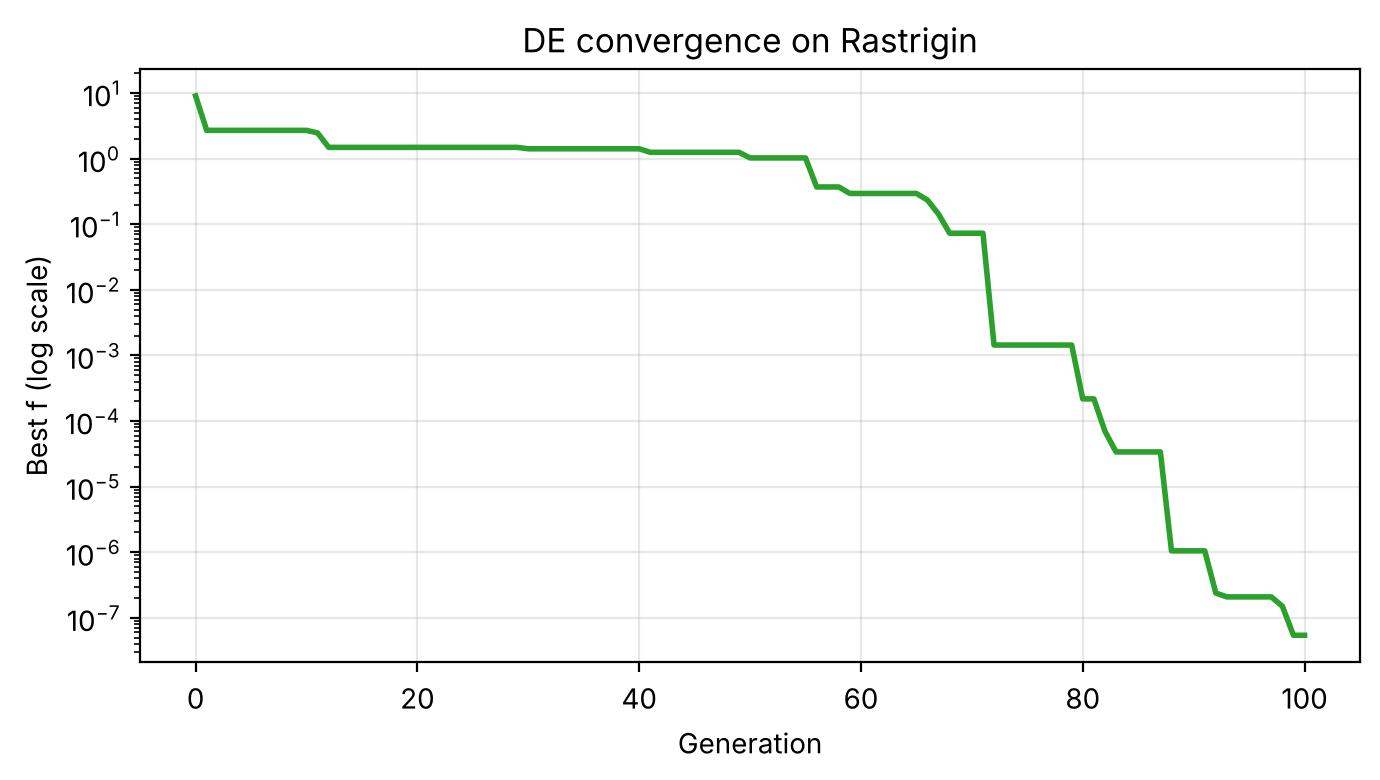

In [5]:
plt.figure(figsize=(7,4)); plt.semilogy(np.array(hist)+1e-12, lw=2, color="tab:green")
plt.xlabel("Generation"); plt.ylabel("Best f (log scale)"); plt.title("DE convergence on Rastrigin")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()